# Lab | Pandas

In this lab, we will be working with the customer data from an insurance company, which can be found in the CSV file located at the following link: https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv

The data includes information such as customer ID, state, gender, education, income, and other variables that can be used to perform various analyses.

Throughout the lab, we will be using the pandas library in Python to manipulate and analyze the data. Pandas is a powerful library that provides various data manipulation and analysis tools, including the ability to load and manipulate data from a variety of sources, including CSV files.

### Data Description

- Customer - Customer ID

- ST - State where customers live

- Gender - Gender of the customer

- Education - Background education of customers 

- Customer Lifetime Value - Customer lifetime value(CLV) is the total revenue the client will derive from their entire relationship with a customer. In other words, is the predicted or calculated value of a customer over their entire duration as a policyholder with the insurance company. It is an estimation of the net profit that the insurance company expects to generate from a customer throughout their relationship with the company. Customer Lifetime Value takes into account factors such as the duration of the customer's policy, premium payments, claim history, renewal likelihood, and potential additional services or products the customer may purchase. It helps insurers assess the long-term profitability and value associated with retaining a particular customer.

- Income - Customers income

- Monthly Premium Auto - Amount of money the customer pays on a monthly basis as a premium for their auto insurance coverage. It represents the recurring cost that the insured person must pay to maintain their insurance policy and receive coverage for potential damages, accidents, or other covered events related to their vehicle.

- Number of Open Complaints - Number of complaints the customer opened

- Policy Type - There are three type of policies in car insurance (Corporate Auto, Personal Auto, and Special Auto)

- Vehicle Class - Type of vehicle classes that customers have Two-Door Car, Four-Door Car SUV, Luxury SUV, Sports Car, and Luxury Car

- Total Claim Amount - the sum of all claims made by the customer. It represents the total monetary value of all approved claims for incidents such as accidents, theft, vandalism, or other covered events.


External Resources: https://towardsdatascience.com/filtering-data-frames-in-pandas-b570b1f834b9

## Challenge 1: Understanding the data

In this challenge, you will use pandas to explore a given dataset. Your task is to gain a deep understanding of the data by analyzing its characteristics, dimensions, and statistical properties.

- Identify the dimensions of the dataset by determining the number of rows and columns it contains.
- Determine the data types of each column and evaluate whether they are appropriate for the nature of the variable. You should also provide suggestions for fixing any incorrect data types.
- Identify the number of unique values for each column and determine which columns appear to be categorical. You should also describe the unique values of each categorical column and the range of values for numerical columns, and give your insights.
- Compute summary statistics such as mean, median, mode, standard deviation, and quartiles to understand the central tendency and distribution of the data for numerical columns. You should also provide your conclusions based on these summary statistics.
- Compute summary statistics for categorical columns and providing your conclusions based on these statistics.

In [2]:
# Your code here - identify the dimensions of the dataset: 4008 rows x 11 columns
import pandas as pd

url = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv"
insurance_company = pd.read_csv(url)
insurance_company

,Customer,ST,GENDER,Education,Customer Lifetime Value,Income,Monthly Premium Auto,Number of Open Complaints,Policy Type,Vehicle Class,Total Claim Amount
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,1/0/00,Personal Auto,Four-Door Car,2.704934
1,QZ44356,Arizona,F,Bachelor,697953.59%,0.0,94.0,1/0/00,Personal Auto,Four-Door Car,1131.464935
2,AI49188,Nevada,F,Bachelor,1288743.17%,48767.0,108.0,1/0/00,Personal Auto,Two-Door Car,566.472247
3,WW63253,California,M,Bachelor,764586.18%,0.0,106.0,1/0/00,Corporate Auto,SUV,529.881344
4,GA49547,Washington,M,High School or Below,536307.65%,36357.0,68.0,1/0/00,Personal Auto,Four-Door Car,17.269323
...,...,...,...,...,...,...,...,...,...,...,...
4003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
insurance_company.shape

(4008, 11)

In [3]:
# Determine the data types of each column and evaluate whether they are appropriate for the nature of the variable. 
# You should also provide suggestions for fixing any incorrect data types.
insurance_company.columns

Index(['Customer', 'ST', 'GENDER', 'Education', 'Customer Lifetime Value',
       'Income', 'Monthly Premium Auto', 'Number of Open Complaints',
       'Policy Type', 'Vehicle Class', 'Total Claim Amount'],
      dtype='str')

In [5]:
insurance_company.dtypes
# Customer Lifetime Value should be float, instead of a string, Number of Open Complaints should be an integer

Customer                         str
ST                               str
GENDER                           str
Education                        str
Customer Lifetime Value          str
Income                       float64
Monthly Premium Auto         float64
Number of Open Complaints        str
Policy Type                      str
Vehicle Class                    str
Total Claim Amount           float64
dtype: object

In [7]:
insurance_company["Customer Lifetime Value"].head()

0            NaN
1     697953.59%
2    1288743.17%
3     764586.18%
4     536307.65%
Name: Customer Lifetime Value, dtype: str

In [8]:
# The values in this column don't make sense as it seems the percentages are impossible. 
insurance_company["Customer Lifetime Value"].unique()

<ArrowStringArray>
[          nan,  '697953.59%', '1288743.17%',  '764586.18%',  '536307.65%',
  '825629.78%',  '538089.86%',  '721610.03%', '2412750.40%',  '738817.81%',
 ...
  '943891.56%', '1050677.17%',  '421391.86%',  '477368.64%',  '544142.01%',
  '284226.69%',  '305955.03%', '2031499.76%',  '323912.47%',  '899704.02%']
Length: 1028, dtype: str

In [9]:
insurance_company["Number of Open Complaints"].head()

0    1/0/00
1    1/0/00
2    1/0/00
3    1/0/00
4    1/0/00
Name: Number of Open Complaints, dtype: str

In [10]:
# I don't understand the format of the data in this column, therefor, I decided to make no changes and not use this data
insurance_company["Number of Open Complaints"].unique()

<ArrowStringArray>
['1/0/00', '1/2/00', '1/1/00', '1/3/00', '1/5/00', '1/4/00', nan]
Length: 7, dtype: str

In [11]:
# Removing the "%" sign and converting to a float may be a solution for this data that seems incorrect
insurance_company["Customer Lifetime Value"] = (
    insurance_company["Customer Lifetime Value"] 
      .str.replace("%", "", regex=False)
)
insurance_company["Customer Lifetime Value"]

0              NaN
1        697953.59
2       1288743.17
3        764586.18
4        536307.65
           ...    
4003           NaN
4004           NaN
4005           NaN
4006           NaN
4007           NaN
Name: Customer Lifetime Value, Length: 4008, dtype: str

In [55]:
#There is a high number of duplicate rows which information is useless
duplicate_mask = insurance_company.duplicated()

display(duplicate_mask)
print("Number of duplicated rows:", duplicate_mask.sum())

0       False
1       False
2       False
3       False
4       False
        ...  
4003     True
4004     True
4005     True
4006     True
4007     True
Length: 4008, dtype: bool

Number of duplicated rows: 2936


In [56]:
#Action: remove the duplicate rows
ins_comp_by_customer = insurance_company.drop_duplicates(
    subset=["customer"],
    keep="first"
)
display(ins_comp_by_customer)

,customer,st,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount,st_original
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,1/0/00,Personal Auto,Four-Door_Car,2.704934,Washington
1,QZ44356,Arizona,F,Bachelor,697953.59,0.0,94.0,1/0/00,Personal Auto,Four-Door_Car,1131.464935,Arizona
2,AI49188,Nevada,F,Bachelor,1288743.17,48767.0,108.0,1/0/00,Personal Auto,Two-Door_Car,566.472247,Nevada
3,WW63253,California,M,Bachelor,764586.18,0.0,106.0,1/0/00,Corporate Auto,SUV,529.881344,California
4,GA49547,Washington,M,High School or Below,536307.65,36357.0,68.0,1/0/00,Personal Auto,Four-Door_Car,17.269323,Washington
...,...,...,...,...,...,...,...,...,...,...,...,...
1067,VJ51327,California,F,High School or Below,2031499.76,63209.0,102.0,1/2/00,Personal Auto,SUV,207.320041,California
1068,GS98873,Arizona,F,Bachelor,323912.47,16061.0,88.0,1/0/00,Personal Auto,Four-Door_Car,633.600000,Arizona
1069,CW49887,California,F,Master,462680.11,79487.0,114.0,1/0/00,Special Auto,SUV,547.200000,California
1070,MY31220,California,F,College,899704.02,54230.0,112.0,1/0/00,Personal Auto,Two-Door_Car,537.600000,California


In [15]:
#suggestion to correct the data type for the column "Customer Lifetime Value" from string to float
insurance_company["Customer Lifetime Value"] = pd.to_numeric(insurance_company["Customer Lifetime Value"], errors="coerce")
insurance_company["Customer Lifetime Value"]

0              NaN
1        697953.59
2       1288743.17
3        764586.18
4        536307.65
           ...    
4003           NaN
4004           NaN
4005           NaN
4006           NaN
4007           NaN
Name: Customer Lifetime Value, Length: 4008, dtype: float64

In [18]:
#Identify the number of unique values for each column and determine which columns appear to be categorical. 
# "st", "Gender", "Education", "Policy Type", "Vehicle Class" are the columns that appear to be categorical
insurance_company.nunique(dropna=False)

Customer                     1072
ST                              9
GENDER                          6
Education                       7
Customer Lifetime Value      1028
Income                        775
Monthly Premium Auto          133
Number of Open Complaints       7
Policy Type                     4
Vehicle Class                   7
Total Claim Amount            762
dtype: int64

In [21]:
#You should also describe the unique values of each categorical column and 
# the range of values for numerical columns, and give your insights.
insurance_company["GENDER"].unique()

<ArrowStringArray>
[nan, 'F', 'M', 'Femal', 'Male', 'female']
Length: 6, dtype: str

In [22]:
# There are similar categories that need to be normalized i found this way of doing it
insurance_company["GENDER"] = (
    insurance_company["GENDER"]
      .str.replace("Femal", "F", regex=False)
      .str.replace("female", "F", regex=False)
      .str.replace("Male", "M", regex=False)
)
insurance_company["GENDER"].unique()

<ArrowStringArray>
[nan, 'F', 'M']
Length: 3, dtype: str

In [40]:
insurance_company["st"].unique()

<ArrowStringArray>
['Washington',    'Arizona',     'Nevada', 'California',     'Oregon',
       'Cali',         'AZ',         'WA',          nan]
Length: 9, dtype: str

In [41]:
# Action: mapping values to a common category
states = pd.Series(["Washington", "Arizona", "Nevada", "California", "Oregon", "Cali", "AZ", "WA", "nan"])
states_map = {
    "Washington": "Washington",
    "Arizona": "Arizona",
    "Nevada": "Nevada",
    "California": "California",
    "Oregon": "Oregon",
    "Cali": "California",
    "AZ": "Arizona",
    "WA": "Washington",
    "nan": "nan"
}
clean_states = states.map(states_map)
display(clean_states)

0    Washington
1       Arizona
2        Nevada
3    California
4        Oregon
5    California
6       Arizona
7    Washington
8           nan
dtype: str

In [51]:
insurance_company["st_original"] = insurance_company["st"]
insurance_company["st"] = insurance_company["st"].map(states_map)
insurance_company

,customer,st,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount,st_original
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,1/0/00,Personal Auto,Four-Door_Car,2.704934,Washington
1,QZ44356,Arizona,F,Bachelor,697953.59,0.0,94.0,1/0/00,Personal Auto,Four-Door_Car,1131.464935,Arizona
2,AI49188,Nevada,F,Bachelor,1288743.17,48767.0,108.0,1/0/00,Personal Auto,Two-Door_Car,566.472247,Nevada
3,WW63253,California,M,Bachelor,764586.18,0.0,106.0,1/0/00,Corporate Auto,SUV,529.881344,California
4,GA49547,Washington,M,High School or Below,536307.65,36357.0,68.0,1/0/00,Personal Auto,Four-Door_Car,17.269323,Washington
...,...,...,...,...,...,...,...,...,...,...,...,...
4003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [52]:
insurance_company["st"].isna().sum()

np.int64(2937)

In [23]:
insurance_company["Education"].value_counts(dropna=False)

Education
NaN                     2937
Bachelor                 324
College                  313
High School or Below     296
Master                    94
Doctor                    37
Bachelors                  7
Name: count, dtype: int64

In [26]:
# Action taken here: Normalizing also the similar categories in this column
insurance_company["Education"] = (
    insurance_company["Education"]
      .str.replace("Bachelorss", "Bachelor", regex=False)
      .str.replace("Bachelors", "Bachelor", regex=False)
)
insurance_company["Education"].unique()

<ArrowStringArray>
['Master', 'Bachelor', 'High School or Below', 'College', 'Doctor', nan]
Length: 6, dtype: str

In [27]:
insurance_company["Policy Type"].unique()

<ArrowStringArray>
['Personal Auto', 'Corporate Auto', 'Special Auto', nan]
Length: 4, dtype: str

In [28]:
insurance_company["Vehicle Class"].unique()

<ArrowStringArray>
['Four-Door Car',  'Two-Door Car',           'SUV',    'Luxury SUV',
    'Sports Car',    'Luxury Car',             nan]
Length: 7, dtype: str

In [29]:
insurance_company["Vehicle Class"] = (
    insurance_company["Vehicle Class"]
      .str.strip()
      .str.replace(" ", "_", regex=False)
)
insurance_company["Vehicle Class"].unique()

<ArrowStringArray>
['Four-Door_Car',  'Two-Door_Car',           'SUV',    'Luxury_SUV',
    'Sports_Car',    'Luxury_Car',             nan]
Length: 7, dtype: str

In [34]:
# Action: normalizing the column names
insurance_company.columns = (
    insurance_company.columns
    .str.lower()
    .str.replace(" ", "_")
)
print(insurance_company.columns.tolist())
insurance_company

['customer', 'st', 'gender', 'education', 'customer_lifetime_value', 'income', 'monthly_premium_auto', 'number_of_open_complaints', 'policy_type', 'vehicle_class', 'total_claim_amount']


,customer,st,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,1/0/00,Personal Auto,Four-Door_Car,2.704934
1,QZ44356,Arizona,F,Bachelor,697953.59,0.0,94.0,1/0/00,Personal Auto,Four-Door_Car,1131.464935
2,AI49188,Nevada,F,Bachelor,1288743.17,48767.0,108.0,1/0/00,Personal Auto,Two-Door_Car,566.472247
3,WW63253,California,M,Bachelor,764586.18,0.0,106.0,1/0/00,Corporate Auto,SUV,529.881344
4,GA49547,Washington,M,High School or Below,536307.65,36357.0,68.0,1/0/00,Personal Auto,Four-Door_Car,17.269323
...,...,...,...,...,...,...,...,...,...,...,...
4003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
#describe the range of values for numerical columns
insurance_company.describe()

,customer_lifetime_value,income,monthly_premium_auto,total_claim_amount
count,1.068000e+03,1071.000000,1071.000000,1071.000000
mean,7.936903e+05,39295.701214,193.234360,404.986909
std,6.434784e+05,30469.427060,1601.190369,293.027260
min,2.004351e+05,0.000000,61.000000,0.382107
25%,4.034080e+05,14072.000000,68.000000,202.157702
50%,5.881742e+05,36234.000000,83.000000,354.729129
75%,8.962872e+05,64631.000000,109.500000,532.800000
max,5.816655e+06,99960.000000,35354.000000,2893.239678


In [43]:
# There seems to be a significant difference between the min and max values
insurance_company.describe().loc[["min", "max"]]

,customer_lifetime_value,income,monthly_premium_auto,total_claim_amount
min,200435.07,0.0,61.0,0.382107
max,5816655.35,99960.0,35354.0,2893.239678


In [44]:
# High number of missing values
display(insurance_company.isna().sum())

customer                     2937
st                           2937
gender                       3054
education                    2937
customer_lifetime_value      2940
income                       2937
monthly_premium_auto         2937
number_of_open_complaints    2937
policy_type                  2937
vehicle_class                2937
total_claim_amount           2937
dtype: int64

In [53]:
#Since there are many rows with missing information, i will drop these rows
insur_comp_without_missing_st = insurance_company.dropna(subset = ["st"])

display(insur_comp_without_missing_st)

,customer,st,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount,st_original
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,1/0/00,Personal Auto,Four-Door_Car,2.704934,Washington
1,QZ44356,Arizona,F,Bachelor,697953.59,0.0,94.0,1/0/00,Personal Auto,Four-Door_Car,1131.464935,Arizona
2,AI49188,Nevada,F,Bachelor,1288743.17,48767.0,108.0,1/0/00,Personal Auto,Two-Door_Car,566.472247,Nevada
3,WW63253,California,M,Bachelor,764586.18,0.0,106.0,1/0/00,Corporate Auto,SUV,529.881344,California
4,GA49547,Washington,M,High School or Below,536307.65,36357.0,68.0,1/0/00,Personal Auto,Four-Door_Car,17.269323,Washington
...,...,...,...,...,...,...,...,...,...,...,...,...
1066,TM65736,Oregon,M,Master,305955.03,38644.0,78.0,1/1/00,Personal Auto,Four-Door_Car,361.455219,Oregon
1067,VJ51327,California,F,High School or Below,2031499.76,63209.0,102.0,1/2/00,Personal Auto,SUV,207.320041,California
1068,GS98873,Arizona,F,Bachelor,323912.47,16061.0,88.0,1/0/00,Personal Auto,Four-Door_Car,633.600000,Arizona
1069,CW49887,California,F,Master,462680.11,79487.0,114.0,1/0/00,Special Auto,SUV,547.200000,California


In [54]:
insur_comp_without_missing_st["st"].isna().sum()

np.int64(0)

<Axes: >

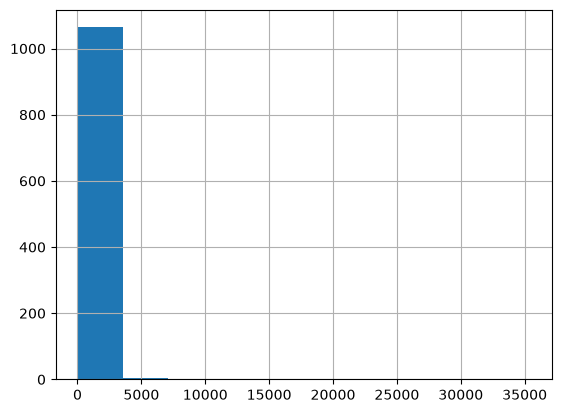

In [75]:
# this output shows that this column ranges from 61.00000 to 35354.00000, with a median of 83.000000 and a mean of 193.234360.
#Since the mean is considerably higher that the median, the distribution may be right-skewed and may contain some high-value outliers
ins_comp_by_customer["monthly_premium_auto"].hist()

In [77]:
ins_comp_by_customer = ins_comp_by_customer.round(2)
# Action: counting the non-missing values in each column of the summary.
ins_comp_by_customer.describe().loc["count"]

customer_lifetime_value    1068.0
income                     1071.0
monthly_premium_auto       1071.0
total_claim_amount         1071.0
Name: count, dtype: float64

In [78]:
ins_comp_by_customer.describe()

,customer_lifetime_value,income,monthly_premium_auto,total_claim_amount
count,1.068000e+03,1071.000000,1071.000000,1071.000000
mean,7.936903e+05,39295.701214,193.234360,404.986928
std,6.434784e+05,30469.427060,1601.190369,293.027079
min,2.004351e+05,0.000000,61.000000,0.380000
25%,4.034080e+05,14072.000000,68.000000,202.160000
50%,5.881742e+05,36234.000000,83.000000,354.730000
75%,8.962872e+05,64631.000000,109.500000,532.800000
max,5.816655e+06,99960.000000,35354.000000,2893.240000


In [83]:
#Action: comparing the relative variation using the coeficient of variation
display(ins_comp_by_customer["customer_lifetime_value"].std().round(2))
display(ins_comp_by_customer["customer_lifetime_value"].mean().round(2))
ins_comp_by_customer["customer_lifetime_value"].std().round(2) / ins_comp_by_customer["customer_lifetime_value"].mean().round(2)

np.float64(643478.41)

np.float64(793690.26)

np.float64(0.8107424803222356)

In [84]:
#Action: comparing the relative variation using the coeficient of variation
display(ins_comp_by_customer["income"].std().round(2))
display(ins_comp_by_customer["income"].mean().round(2))
ins_comp_by_customer["income"].std().round(2) / ins_comp_by_customer["income"].mean().round(2)

np.float64(30469.43)

np.float64(39295.7)

np.float64(0.7753884012754577)

In [85]:
#Action: comparing the relative variation using the coeficient of variation - there is a greater variability of the data
display(ins_comp_by_customer["monthly_premium_auto"].std().round(2))
display(ins_comp_by_customer["monthly_premium_auto"].mean().round(2))
ins_comp_by_customer["monthly_premium_auto"].std().round(2) / ins_comp_by_customer["monthly_premium_auto"].mean().round(2)

np.float64(1601.19)

np.float64(193.23)

np.float64(8.286446204005589)

In [73]:
# The difference between min and max values may need investigation as it seem far from the mean and median in most of the columns
ins_comp_by_customer[["customer_lifetime_value", "income", "monthly_premium_auto", "total_claim_amount"]].agg(["min", "max", "mean", "median"])

,customer_lifetime_value,income,monthly_premium_auto,total_claim_amount
min,2.004351e+05,0.000000,61.00000,0.380000
max,5.816655e+06,99960.000000,35354.00000,2893.240000
mean,7.936903e+05,39295.701214,193.23436,404.986928
median,5.881742e+05,36234.000000,83.00000,354.730000


In [91]:
categorical_summary = insurance_company.select_dtypes(
    include=["str", 
             "category"]    ]
).describe()

print(categorical_summary)

       customer          st gender education number_of_open_complaints  \
count      1071        1071    954      1071                      1071   
unique     1071           5      2         5                         6   
top     RB50392  California      F  Bachelor                    1/0/00   
freq          1         331    502       331                       830   

          policy_type  vehicle_class st_original  
count            1071           1071        1071  
unique              3              6           5  
top     Personal Auto  Four-Door_Car  California  
freq              780            576         331  


In [93]:
# The customers are geografically distributed through 5 states, taking in consideration the non-missing values
# The columns "gender" contains 118 missing values and this should be handled in case an analysis requires this data. 
#The most common gender is "Female" with a small difference from "Male"
# "Bachelor" is the most common education level and "Doctor" the less common.
# Concerning the "policy type", the "Personal Auto" is the most common, wiht a large difference from the others
# The most common Vehicle Class is "Four-Door_Car", with a large difference from th e others

for column in ins_comp_by_customer.select_dtypes(
    include=["str", "category"]
).columns:
    print(f"\n{column}")
    print(ins_comp_by_customer[column].value_counts(dropna=False))


customer
customer
RB50392    1
QZ44356    1
AI49188    1
WW63253    1
GA49547    1
          ..
VJ51327    1
GS98873    1
CW49887    1
MY31220    1
NaN        1
Name: count, Length: 1072, dtype: int64

st
st
California    331
Oregon        320
Arizona       211
Washington    111
Nevada         98
NaN             1
Name: count, dtype: int64

gender
gender
F      502
M      452
NaN    118
Name: count, dtype: int64

education
education
Bachelor                331
College                 313
High School or Below    296
Master                   94
Doctor                   37
NaN                       1
Name: count, dtype: int64

number_of_open_complaints
number_of_open_complaints
1/0/00    830
1/1/00    138
1/2/00     50
1/3/00     34
1/4/00     13
1/5/00      6
NaN         1
Name: count, dtype: int64

policy_type
policy_type
Personal Auto     780
Corporate Auto    234
Special Auto       57
NaN                 1
Name: count, dtype: int64

vehicle_class
vehicle_class
Four-Door_Car    576
Tw

In [94]:
# The most common location is California, with the higher percentage of customers and Nevada, the lowest. 
ins_comp_by_customer["st"].value_counts(normalize=True, dropna=False) * 100

st
California    30.876866
Oregon        29.850746
Arizona       19.682836
Washington    10.354478
Nevada         9.141791
NaN            0.093284
Name: proportion, dtype: float64

In [95]:
ins_comp_by_customer.select_dtypes(
    include=["str", "category"]
).isna().sum()

customer                       1
st                             1
gender                       118
education                      1
number_of_open_complaints      1
policy_type                    1
vehicle_class                  1
st_original                    1
dtype: int64

## Challenge 2: analyzing the data

### Exercise 1

The marketing team wants to know the top 5 less common customer locations. Create a pandas Series object that contains the customer locations and their frequencies, and then retrieve the top 5 less common locations in ascending order.

In [87]:
# Your code here
customer_locations = insurance_company["st"].value_counts()

print(customer_locations)

st
California    331
Oregon        320
Arizona       211
Washington    111
Nevada         98
Name: count, dtype: int64


In [88]:
customer_locations = insurance_company["st"].value_counts()

least_common_locations = (
    customer_locations
    .sort_values(ascending=True)
    .head(5)
)

print(least_common_locations)

st
Nevada         98
Washington    111
Arizona       211
Oregon        320
California    331
Name: count, dtype: int64


### Exercise 2

The sales team wants to know the total number of policies sold for each type of policy. Create a pandas Series object that contains the policy types and their total number of policies sold, and then retrieve the policy type with the highest number of policies sold.

*Hint:*
- *Using value_counts() method simplifies this analysis.*
- *Futhermore, there is a method that returns the index of the maximum value in a column or row.*


In [96]:
# Your code here
policy_sales = insurance_company["policy_type"].value_counts()

print(policy_sales)

policy_type
Personal Auto     780
Corporate Auto    234
Special Auto       57
Name: count, dtype: int64


In [97]:
policy_sales.idxmax()

'Personal Auto'

### Exercise 3

The sales team wants to know if customers with Personal Auto have a lower income than those with Corporate Auto. How does the average income compare between the two policy types?

- Use *loc* to create two dataframes: one containing only Personal Auto policies and one containing only Corporate Auto policies.
- Calculate the average income for each policy.
- Print the results.

In [100]:
# Your code here
personal_auto = ins_comp_by_customer.loc[ins_comp_by_customer["policy_type"] == "Personal Auto"].copy()

corporate_auto = ins_comp_by_customer.loc[ins_comp_by_customer["policy_type"] == "Corporate Auto"].copy()

personal_average_income = personal_auto["income"].mean()
corporate_average_income = corporate_auto["income"].mean()

print("Average income for Personal Auto policies:", personal_average_income)
print("Average income for Corporate Auto policies:", corporate_average_income)

Average income for Personal Auto policies: 38180.69871794872
Average income for Corporate Auto policies: 41390.31196581197


### Bonus: Exercise 4


Your goal is to identify customers with a high policy claim amount.

Instructions:

- Review again the statistics for total claim amount to gain an understanding of the data.
- To identify potential areas for improving customer retention and profitability, we want to focus on customers with a high policy claim amount. Consider customers with a high policy claim amount to be those in the top 25% of the total claim amount. Create a pandas DataFrame object that contains information about customers with a policy claim amount greater than the 75th percentile.
- Use DataFrame methods to calculate summary statistics about the high policy claim amount data. 

*Note: When analyzing data, we often want to focus on certain groups of values to gain insights. Percentiles are a useful tool to help us define these groups. A percentile is a measure that tells us what percentage of values in a dataset are below a certain value. For example, the 75th percentile represents the value below which 75% of the data falls. Similarly, the 25th percentile represents the value below which 25% of the data falls. When we talk about the top 25%, we are referring to the values that fall above the 75th percentile, which represent the top quarter of the data. On the other hand, when we talk about the bottom 25%, we are referring to the values that fall below the 25th percentile, which represent the bottom quarter of the data. By focusing on these groups, we can identify patterns and trends that may be useful for making decisions and taking action.*

*Hint: look for a method that gives you the percentile or quantile 0.75 and 0.25 for a Pandas Series.*

*Hint 2: check `Boolean selection according to the values of a single column` in https://towardsdatascience.com/filtering-data-frames-in-pandas-b570b1f834b9*

In [105]:
# Your code here
claim_75th_percentile = ins_comp_by_customer["total_claim_amount"].quantile(0.75)

customers_high_claims = ins_comp_by_customer.loc[
    ins_comp_by_customer["total_claim_amount"] > claim_75th_percentile
].copy()

customers_high_claims

,customer,st,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount,st_original
1,QZ44356,Arizona,F,Bachelor,697953.59,0.0,94.0,1/0/00,Personal Auto,Four-Door_Car,1131.46,Arizona
2,AI49188,Nevada,F,Bachelor,1288743.17,48767.0,108.0,1/0/00,Personal Auto,Two-Door_Car,566.47,Nevada
17,OE15005,California,NaN,College,394524.16,28855.0,101.0,1/0/00,Personal Auto,SUV,647.44,California
23,TZ98966,Nevada,NaN,Bachelor,245019.10,0.0,73.0,1/3/00,Corporate Auto,Four-Door_Car,554.38,Nevada
26,US89481,California,NaN,Bachelor,394637.21,0.0,111.0,1/0/00,Personal Auto,Four-Door_Car,799.20,California
...,...,...,...,...,...,...,...,...,...,...,...,...
1059,YG44474,Oregon,M,College,1401472.13,54193.0,117.0,1/0/00,Corporate Auto,SUV,720.75,Oregon
1061,RY92647,California,F,Bachelor,1050677.17,0.0,92.0,1/0/00,Personal Auto,Four-Door_Car,546.52,California
1068,GS98873,Arizona,F,Bachelor,323912.47,16061.0,88.0,1/0/00,Personal Auto,Four-Door_Car,633.60,Arizona
1069,CW49887,California,F,Master,462680.11,79487.0,114.0,1/0/00,Special Auto,SUV,547.20,California
